In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split

from sklearn.metrics import r2_score,mean_squared_error

In [2]:
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\Python for Data Science  NOI  APR 2026   Class 20 Python for Data Science  NOI  APR 2026\loans - 1782056769161.csv")

In [3]:
df.head()

,credit_score,annual_income,loan_amount,dti,emp_length_years,term_months,home_ownership,loan_purpose,interest_rate
0,783,104361.0,6022,18.4,5.0,36,RENT,debt_consolidation,8.65
1,664,93162.0,26734,12.0,2.0,60,MORTGAGE,credit_card,12.75
2,692,26099.0,9768,26.2,5.0,36,MORTGAGE,debt_consolidation,12.68
3,712,81804.0,9522,15.0,7.0,36,RENT,home_improvement,11.08
4,647,109970.0,17154,12.9,1.0,36,RENT,debt_consolidation,15.56


In [4]:
df.shape

(260, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      260 non-null    int64  
 1   annual_income     257 non-null    float64
 2   loan_amount       260 non-null    int64  
 3   dti               258 non-null    float64
 4   emp_length_years  257 non-null    float64
 5   term_months       260 non-null    int64  
 6   home_ownership    260 non-null    str    
 7   loan_purpose      260 non-null    str    
 8   interest_rate     260 non-null    float64
dtypes: float64(4), int64(3), str(2)
memory usage: 23.7 KB


In [6]:
df.isnull().sum()

credit_score        0
annual_income       3
loan_amount         0
dti                 2
emp_length_years    3
term_months         0
home_ownership      0
loan_purpose        0
interest_rate       0
dtype: int64

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credit_score,260.0,688.357692,52.191796,564.00,656.7500,687.00,723.00,814.00
annual_income,257.0,76526.050584,123080.824733,22000.00,51572.0000,68706.00,86186.00,2000000.00
loan_amount,260.0,14999.476923,6660.948464,2000.00,10228.5000,15222.00,19607.00,32576.00
dti,258.0,18.558527,6.395635,3.00,14.0500,18.20,23.30,36.20
emp_length_years,257.0,6.949416,3.908296,0.00,4.0000,7.00,10.00,16.00
term_months,260.0,44.953846,11.629321,36.00,36.0000,36.00,60.00,60.00
interest_rate,260.0,12.468577,1.617418,8.65,11.3225,12.44,13.68,16.78


In [8]:
#missing values

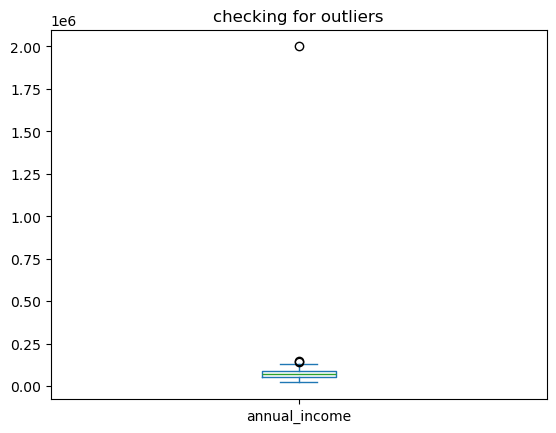

In [9]:
df['annual_income'].plot(kind='box',title='checking for outliers')
plt.show()

In [10]:
df=df[df['annual_income']<=500000]
df=df.reset_index(drop=True)
df.shape

(256, 9)

In [11]:
#handling the missing values
for column in ['annual_income','emp_length_years','dti']:
    column_median=df[column].median()
    df[column]=df[column].fillna(column_median)
df.isnull().sum()    

credit_score        0
annual_income       0
loan_amount         0
dti                 0
emp_length_years    0
term_months         0
home_ownership      0
loan_purpose        0
interest_rate       0
dtype: int64

In [12]:
#converting text columns into 0/1 dummy columns so the model can use them
df_ready=pd.get_dummies(df,columns=['home_ownership','loan_purpose'],drop_first=True)
for column in df_ready.columns:
    if df_ready[column].dtype==bool:
        df_ready[column]=df_ready[column].astype(int)
df_ready.head()

,credit_score,annual_income,loan_amount,dti,emp_length_years,term_months,interest_rate,home_ownership_OWN,home_ownership_RENT,loan_purpose_debt_consolidation,loan_purpose_home_improvement,loan_purpose_major_purchase
0,783,104361.0,6022,18.4,5.0,36,8.65,0,1,1,0,0
1,664,93162.0,26734,12.0,2.0,60,12.75,0,0,0,0,0
2,692,26099.0,9768,26.2,5.0,36,12.68,0,0,1,0,0
3,712,81804.0,9522,15.0,7.0,36,11.08,0,1,0,1,0
4,647,109970.0,17154,12.9,1.0,36,15.56,0,1,1,0,0


In [13]:
df_ready.info()

<class 'pandas.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   credit_score                     256 non-null    int64  
 1   annual_income                    256 non-null    float64
 2   loan_amount                      256 non-null    int64  
 3   dti                              256 non-null    float64
 4   emp_length_years                 256 non-null    float64
 5   term_months                      256 non-null    int64  
 6   interest_rate                    256 non-null    float64
 7   home_ownership_OWN               256 non-null    int64  
 8   home_ownership_RENT              256 non-null    int64  
 9   loan_purpose_debt_consolidation  256 non-null    int64  
 10  loan_purpose_home_improvement    256 non-null    int64  
 11  loan_purpose_major_purchase      256 non-null    int64  
dtypes: float64(4), int64(8)
memory us

In [14]:
y=df_ready['interest_rate']
x=df_ready.drop(columns=['interest_rate'])
print("features:",list(x.columns))

features: ['credit_score', 'annual_income', 'loan_amount', 'dti', 'emp_length_years', 'term_months', 'home_ownership_OWN', 'home_ownership_RENT', 'loan_purpose_debt_consolidation', 'loan_purpose_home_improvement', 'loan_purpose_major_purchase']


In [15]:
#build model

In [16]:
X_all=sm.add_constant(x)
model_all=sm.OLS(y,X_all).fit()
print(model_all.summary())

# p-value for every column must be less then 0.05 if it is not then those columns are use less we have to drop that columns 

                            OLS Regression Results                            
Dep. Variable:          interest_rate   R-squared:                       0.696
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     50.86
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           7.34e-57
Time:                        20:39:57   Log-Likelihood:                -334.93
No. Observations:                 256   AIC:                             693.9
Df Residuals:                     244   BIC:                             736.4
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

In [17]:
# VIF:is any features a near-copy of other?(the VIF value must be under the 10 if it is not then drop that columns)
vif_table = pd.DataFrame()
vif_table["feature"] = x.columns
vif_table["VIF"] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
vif_table.sort_values("VIF", ascending=False)

,feature,VIF
8,loan_purpose_debt_consolidation,1.521341
9,loan_purpose_home_improvement,1.403317
6,home_ownership_OWN,1.249071
10,loan_purpose_major_purchase,1.227952
7,home_ownership_RENT,1.192439
4,emp_length_years,1.063128
0,credit_score,1.054647
2,loan_amount,1.052489
1,annual_income,1.048085
3,dti,1.029647


In [18]:
#drop the weak features
weak_features=["home_ownership_OWN","loan_purpose_major_purchase","loan_purpose_home_improvement","loan_purpose_debt_consolidation"]
X_small=x.drop(columns=weak_features)
x_small=sm.add_constant(X_small)
model_small=sm.OLS(y,x_small).fit()
print(model_small.summary())

                            OLS Regression Results                            
Dep. Variable:          interest_rate   R-squared:                       0.685
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     77.12
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.19e-58
Time:                        20:39:57   Log-Likelihood:                -339.54
No. Observations:                 256   AIC:                             695.1
Df Residuals:                     248   BIC:                             723.4
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  24.0152    

In [19]:
#train the data set
X_train,X_test,y_train,y_test=train_test_split(X_small,y,test_size=0.2,random_state=1)

x_train=sm.add_constant(X_train)
final_model=sm.OLS(y_train,x_train).fit()

x_test=sm.add_constant(X_test)
y_pred=final_model.predict(x_test)

In [20]:
final_model.params

const                  24.368617
credit_score           -0.020656
annual_income          -0.000014
loan_amount             0.000055
dti                     0.089447
emp_length_years       -0.055731
term_months             0.014783
home_ownership_RENT     1.078916
dtype: float64

In [21]:
y_pred

183    11.924957
34     14.572040
185    12.931064
233    11.355173
216    11.959224
181    15.399243
160    13.032173
27     13.069813
145    14.487459
187    12.553177
255    10.884432
62     14.905653
4      13.145226
229    12.053623
44     10.311172
163    11.330250
249    11.394190
51     12.599525
182    13.531052
234    14.236521
73     11.114975
99     11.796688
189    14.137151
226    14.255719
230    12.321632
88      9.760171
38     12.814880
236    10.471573
130    13.711237
244    12.153943
67     10.609920
12     12.474040
93     10.140748
78     11.340700
85      9.008670
213    12.711099
39     12.313735
247    15.281021
248    13.894306
254    14.148011
245    14.756315
231    12.139084
120    13.086108
31     12.221476
18      9.957081
220    12.960060
168    13.209567
19     12.792789
242    11.313309
58     13.704963
33     13.277234
106    14.076136
dtype: float64

In [22]:
# error measures on the test set (smaller is better)
test_r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = np.mean(np.abs(y_test - y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("Test R-square:", round(test_r2, 3))
print("RMSE (typical error in rate points):", round(rmse, 2))
print("MAE  (average error in rate points):", round(mae, 2))
print("MAPE (average percent error):", round(mape, 1), "%")


Test R-square: 0.679
RMSE (typical error in rate points): 0.96
MAE  (average error in rate points): 0.73
MAPE (average percent error): 5.9 %


In [23]:
train_pred = final_model.predict(x_train)
residuals = y_train - train_pred

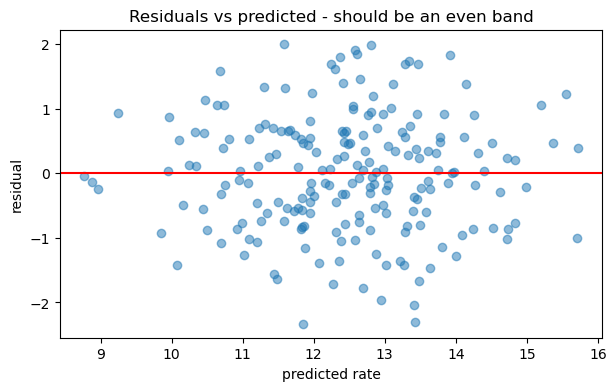

In [24]:
# Homoscedasticity: error spread even across predictions (no funnel)
plt.figure(figsize=(7,4))
plt.scatter(train_pred, residuals, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("predicted rate")
plt.ylabel("residual")
plt.title("Residuals vs predicted - should be an even band")
plt.show()

In [25]:
print("Intercept =", round(final_model.params["const"], 3))
for name in X_small.columns:
    coef = final_model.params[name]
    print("   +", round(coef, 5), "*", name)

Intercept = 24.369
   + -0.02066 * credit_score
   + -1e-05 * annual_income
   + 6e-05 * loan_amount
   + 0.08945 * dti
   + -0.05573 * emp_length_years
   + 0.01478 * term_months
   + 1.07892 * home_ownership_RENT


In [26]:
final_model.params["const"]

np.float64(24.368617182460728)

In [27]:
new_applicants = pd.DataFrame([
    {"credit_score": 780, "annual_income": 120000, "loan_amount": 8000,  "dti": 10.0,
     "emp_length_years": 12, "term_months": 36, "home_ownership": "OWN",      "loan_purpose": "major_purchase"},
    {"credit_score": 690, "annual_income": 70000,  "loan_amount": 15000, "dti": 18.0,
     "emp_length_years": 6,  "term_months": 36, "home_ownership": "MORTGAGE", "loan_purpose": "credit_card"},
    {"credit_score": 610, "annual_income": 45000,  "loan_amount": 25000, "dti": 30.0,
     "emp_length_years": 2,  "term_months": 60, "home_ownership": "RENT",     "loan_purpose": "debt_consolidation"},
])
new_applicants

,credit_score,annual_income,loan_amount,dti,emp_length_years,term_months,home_ownership,loan_purpose
0,780,120000,8000,10.0,12,36,OWN,major_purchase
1,690,70000,15000,18.0,6,36,MORTGAGE,credit_card
2,610,45000,25000,30.0,2,60,RENT,debt_consolidation
